# 4.7 Training and evaluating a network: the lab, the clinic and the rubric

A network that trains is not yet a network you can trust. This lab holds one task fixed and changes one decision at a time, so you see what each decision costs, measured with seeds and on a clean test set. The decisions fall under three pillars:

| Pillar | Station | Question you answer with a number |
|---|---|---|
| Data | 3 | What do wrong labels, a rare class, mixed sample quality and the amount of data cost? |
| Architecture | 4 | How wide, how deep, and is it better than a linear baseline? |
| Training | 5 | Starting weights, learning rate, batch size, and when to stop |
| (all three) | 6 | How much should you trust a prediction, inside and outside the training range? |
| | 7 | Six broken runs: diagnose them from the curves |

The task is a synthetic lithology table, so every defect is planted by us and its cost can be measured exactly. The same decisions on real seismograms are the subject of the optional [training clinic](mlgeo_4.7_training_clinic.ipynb) and of the homework ([Homework_DL](Homework_DL.ipynb)). Every training run takes about a second on a laptop CPU.

**Two sessions.** Sections 1 to 3 on Wednesday Nov 25, sections 4 to 7 on Monday Nov 30. To resume, run sections 1 and 2 again (a few seconds), then go to section 4.

🖥️ [**Training and evaluating any network: the loop and the leaderboard (reference slides)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec24a_train_and_evaluate.html)

🖥️ [**Lecture slides — Session 24 — lab I (Wed Nov 25)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec24_three_pillars_lab_I.html)

🖥️ [**Lecture slides — Session 25 — lab II (Mon Nov 30)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec25_three_pillars_lab_II.html)

## 1. The data: three lithologies from nine measurements

Classify rock samples as granite, basalt or andesite from 9 features: seven major-element oxides (wt%), density (g/cm$^3$) and magnetic susceptibility (SI). The table comes from `mlgeo_synth.geochem_table`. A hidden differentiation index drives the oxides of each sample together (more evolved: more SiO$_2$ and K$_2$O, less FeO, MgO and CaO), and andesite is rare by construction (10% of samples).

The raw table is almost perfectly separable, which no field instrument delivers. Every dataset below therefore carries a measurement-noise floor of one standard deviation per feature, on the training, validation and test sets alike.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, recall_score

import mlgeo_synth

# Device-agnostic setup. The models in this lab are tiny (a few thousand
# parameters), and for models this small the CPU is faster than an
# accelerator because kernel-launch overhead dominates. We detect the
# accelerator to show the pattern, then deliberately train on CPU.
detected = torch.device("cuda" if torch.cuda.is_available()
                        else "mps" if torch.backends.mps.is_available()
                        else "cpu")
device = torch.device("cpu")
print(f"accelerator detected: {detected}; using: {device}")

torch.manual_seed(0)
np.random.seed(0)

accelerator detected: mps; using: cpu


In [2]:
df = mlgeo_synth.geochem_table(n=3000, label_noise=0.0, seed=0)
print(df.shape)
df.head()

(3000, 10)


,SIO2,AL2O3,FEO,MGO,CAO,NA2O,K2O,density_g_cm3,mag_susc_si,label
0,48.271072,14.550932,9.584487,7.786032,11.408379,2.258560,0.812292,2.964359,0.001658,basalt
1,72.178440,14.659499,2.189115,1.033966,2.353944,4.054576,4.720737,2.667887,0.000087,granite
2,73.667158,13.452573,1.191274,0.140795,1.781264,4.588104,5.456854,2.651066,0.000108,granite
3,69.915112,14.344166,4.565303,2.014665,2.891233,3.588710,2.962119,2.647545,0.000129,granite
4,50.691400,15.028301,7.642222,6.779043,10.832978,2.687062,0.742804,3.009791,0.001025,basalt


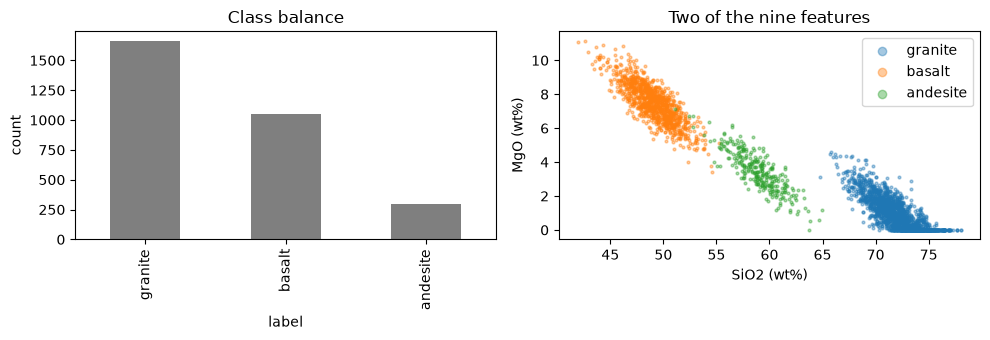

In [3]:
CLASSES = ["granite", "basalt", "andesite"]
FEATURES = [c for c in df.columns if c != "label"]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["label"].value_counts().loc[CLASSES].plot.bar(ax=ax[0], color="tab:gray")
ax[0].set_ylabel("count"); ax[0].set_title("Class balance")
for c in CLASSES:
    sub = df[df["label"] == c]
    ax[1].scatter(sub["SIO2"], sub["MGO"], s=4, alpha=0.4, label=c)
ax[1].set_xlabel("SiO2 (wt%)"); ax[1].set_ylabel("MgO (wt%)")
ax[1].set_title("Two of the nine features"); ax[1].legend(markerscale=3)
plt.tight_layout()

## 2. Train one network, step by step

The same order as notebooks 4.1 and 4.2: split the data, design the model, choose the loss and the optimizer, write the training loop, train and look at the learning curve, compare with a baseline. Every station below reuses these pieces and changes one of them.

### 2.1 Split the data first

`make_data` draws a table, splits it into training (75%) and validation (25%) sets, scales the features with statistics of the training set only, and adds the noise floor. The **test set** is drawn separately, with its own seed, and is always clean: no flipped labels and no defects beyond the noise floor, even when we corrupt the training data on purpose. That is how we measure what a defect costs.

The keyword arguments are the knobs of station 3: `label_noise` flips a fraction of labels, `minority_keep` keeps a fraction of the andesites, `relabel` applies structured label errors, `hetero_sigma` gives each training sample its own noise level.

In [4]:
def table_to_xy(frame):
    X = frame[FEATURES].to_numpy(dtype=np.float32)
    y = frame["label"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    return X, y.astype(np.int64)


def make_data(n_train=3000, label_noise=0.0, minority_keep=1.0,
              feature_noise=0.0, base_noise=1.0, relabel=None,
              hetero_sigma=None, seed=0):
    '''Train/val splits with optional corruption; test set always clean.

    label_noise   : fraction of flipped labels in train+val (uniform flips)
    minority_keep : fraction of andesite (minority) samples kept in train+val
    feature_noise : std of EXTRA Gaussian noise added to standardized features
                    (sensor degradation, in units of one feature std)
    base_noise    : the shared measurement-noise floor on all splits
    relabel       : optional function frame -> frame applied after generation,
                    for structured label errors (Section 3.1)
    hetero_sigma  : optional tuple of noise levels; each TRAINING sample draws
                    its noise floor from these instead of base_noise, and the
                    per-sample sigma comes back as a 7th element (Section 3.3)
    '''
    frame = mlgeo_synth.geochem_table(n=n_train, label_noise=label_noise, seed=seed)
    if relabel is not None:
        frame = relabel(frame)
    if minority_keep < 1.0:
        minority = frame[frame["label"] == "andesite"]
        drop = minority.sample(frac=1.0 - minority_keep, random_state=seed).index
        frame = frame.drop(index=drop)
    X, y = table_to_xy(frame)
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.25,
                                          random_state=seed, stratify=y)
    # fixed clean test set, drawn from the same generator with a held seed
    Xte, yte = table_to_xy(mlgeo_synth.geochem_table(n=1500, label_noise=0.0, seed=987))
    scaler = StandardScaler().fit(Xtr)          # fit on train only
    Xtr, Xva, Xte = (scaler.transform(a) for a in (Xtr, Xva, Xte))
    rngs = [np.random.default_rng(1000 * seed + k) for k in range(3)]
    # measurement-noise floor on every split; extra sensor noise on top
    if hetero_sigma is None:
        Xtr = Xtr + rngs[0].normal(0, 1, Xtr.shape) * np.hypot(base_noise, feature_noise)
    else:                      # per-sample noise floor on the training split
        sigma_tr = rngs[0].choice(hetero_sigma, size=len(Xtr)).astype(np.float32)
        Xtr = Xtr + rngs[0].normal(0, 1, Xtr.shape) * sigma_tr[:, None]
    Xva = Xva + rngs[1].normal(0, 1, Xva.shape) * np.hypot(base_noise, feature_noise)
    Xte = Xte + rngs[2].normal(0, 1, Xte.shape) * base_noise
    t = lambda a: torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32)
    out = (t(Xtr), torch.as_tensor(ytr), t(Xva), torch.as_tensor(yva),
           t(Xte), torch.as_tensor(yte))
    if hetero_sigma is not None:
        out = out + (torch.as_tensor(sigma_tr),)
    return out



data = make_data(seed=5)          # the reference dataset of sections 2, 4 and 6
print("train", tuple(data[0].shape), "| validation", tuple(data[2].shape), "| test", tuple(data[4].shape))

train (2250, 9) | validation (750, 9) | test (1500, 9)


### 2.2 Design the model

A multilayer perceptron with `depth` hidden layers of `width` units, ReLU after each, and a last linear layer with one score per class. With `depth=0` it is a single linear layer: multinomial logistic regression, the baseline of 2.6.

In [5]:
class MLP(nn.Module):
    def __init__(self, width=32, depth=2, dropout=0.0, n_in=9, n_out=3):
        super().__init__()
        layers, d = [], n_in
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = width
        layers.append(nn.Linear(d, n_out))   # raw logits; softmax lives in the loss
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters())

### 2.3 Loss and optimizer

Three classes: cross-entropy, with the softmax inside the loss (the network outputs three raw scores). The optimizer is Adam with a learning rate of 0.001, the default of this course. `train_model` below builds the optimizer itself, so a station can change the learning rate, the optimizer or the loss.

In [6]:
loss_fn = nn.CrossEntropyLoss()


def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X.to(device)).argmax(1).cpu() == y).float().mean().item()

### 2.4 The training loop

One **epoch** is one pass over the training samples: shuffle their order, cut it into batches, and for each batch zero the gradients, compute the loss of the batch, the gradients, and one update. After each epoch the loop measures the training and validation loss and accuracy, and keeps a copy of the weights each time the validation loss reaches a new low: the **checkpoint**. At the end the model gets back the weights of its best epoch. The loss curves are the diagnostic instrument of the whole lab.

![The loop every station of this lab changes one piece of (lecture 23)](../slides/2026/figs/lec23_rnn/training_loop.png)

### Your turn (1): one epoch

`one_epoch` below already shuffles the samples and cuts them into batches. Write the four lines that go inside the loop, for the batch `idx`: zero the gradients with `opt.zero_grad()`, compute the loss of the batch with `criterion` (the network's scores `model(X[idx])` against the labels `y[idx]`), compute the gradients with `.backward()`, and update the weights with `opt.step()`. They are the four lines of the loop on the lecture 24a slide, and the same four in every notebook of this chapter.

In [7]:
def one_epoch(model, opt, criterion, X, y, batch_size, g):
    '''One pass over the training samples in a new random order; one update per batch.'''
    order = torch.randperm(len(X), generator=g)    # a new order every epoch
    for i in range(0, len(X), batch_size):
        idx = order[i:i + batch_size]              # the next batch
        pass   # your four lines here

*Answer below (click to open it).*

In [8]:
def one_epoch(model, opt, criterion, X, y, batch_size, g):
    order = torch.randperm(len(X), generator=g)
    for i in range(0, len(X), batch_size):
        idx = order[i:i + batch_size]
        opt.zero_grad()                            # gradients from the last batch would add up
        loss = criterion(model(X[idx]), y[idx])    # mean loss over the batch
        loss.backward()                            # one gradient per weight
        opt.step()                                 # the update

`train_model` wraps `one_epoch` with the optimizer, the curves and the checkpoint. Every station below calls it and changes one argument: the learning rate, the batch size, the optimizer, the loss (`criterion`), or the data. `keep_best=False` keeps the weights of the last epoch instead (section 5.4 compares the two).

In [9]:
def train_model(model, data, epochs=25, lr=1e-3, batch_size=256, weight_decay=0.0,
                optimizer="adam", scheduler=None, seed=0, criterion=None, keep_best=True):
    '''Train with one_epoch; return the per-epoch curves.
    criterion: the training loss (default: cross-entropy); the curves always use cross-entropy.
    keep_best: give the model back the weights of the epoch with the lowest validation loss.'''
    criterion = criterion or loss_fn
    Xtr, ytr, Xva, yva = data[:4]
    model.to(device)
    opt_cls = {"adam": torch.optim.Adam, "sgd": torch.optim.SGD}[optimizer]
    opt = opt_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = scheduler(opt) if scheduler is not None else None
    g = torch.Generator().manual_seed(seed)       # the order of the batches, reproducible
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "lr"]}
    hist["best_epoch"] = None
    best, best_state = np.inf, None
    for epoch in range(epochs):
        model.train()                              # dropout on
        one_epoch(model, opt, criterion, Xtr, ytr, batch_size, g)
        model.eval()                               # dropout off
        with torch.no_grad():                      # measuring, not training
            hist["train_loss"].append(loss_fn(model(Xtr), ytr).item())
            hist["val_loss"].append(loss_fn(model(Xva), yva).item())
        hist["train_acc"].append(accuracy(model, Xtr, ytr))
        hist["val_acc"].append(accuracy(model, Xva, yva))
        hist["lr"].append(opt.param_groups[0]["lr"])
        if hist["val_loss"][-1] < best:            # the checkpoint
            best, hist["best_epoch"] = hist["val_loss"][-1], epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if sched is not None:
            sched.step()
    if keep_best and best_state is not None:       # None if the loss was never finite
        model.load_state_dict(best_state)
    return hist


def plot_history(hist, ax=None, title="", logy=False):
    '''Train/validation loss curves for one run.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 3))
    ax.plot(hist["train_loss"], label="train")
    ax.plot(hist["val_loss"], label="validation")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss")
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    return ax

### 2.5 Train, and plot the learning curve

4995 weights; best epoch 14, validation accuracy 0.944
last epoch: training loss 0.115, validation loss 0.153


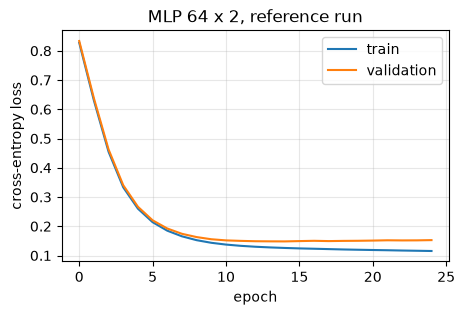

In [10]:
torch.manual_seed(7)
best_mlp = MLP(width=64, depth=2)
hist_ref = train_model(best_mlp, data, epochs=25, seed=7)
plot_history(hist_ref, title="MLP 64 x 2, reference run")
b = hist_ref["best_epoch"]
print(f"{count_params(best_mlp)} weights; best epoch {b}, validation accuracy {hist_ref['val_acc'][b]:.3f}")
print(f"last epoch: training loss {hist_ref['train_loss'][-1]:.3f}, validation loss {hist_ref['val_loss'][-1]:.3f}")

Both curves fall together and flatten after about 10 epochs. The small gap that opens after that (at the last epoch, training loss 0.115 and validation 0.153) is the start of fitting the training samples rather than the classes; at 25 epochs it is still small. The validation loss was lowest at epoch 14 (counted from 0), so `train_model` gave the model back the weights of that epoch.

### 2.6 Compare with a baseline

A score means something only next to a simpler model on the same data. For classification, that is multinomial logistic regression: our `MLP` with `depth=0`.

In [11]:
torch.manual_seed(7)
logistic = MLP(width=1, depth=0)     # depth=0 -> a single linear layer
train_model(logistic, data, epochs=25, seed=7)

print(f"logistic baseline ({count_params(logistic):5d} params): test acc {accuracy(logistic, *data[4:6]):.3f}")
print(f"MLP 64x2          ({count_params(best_mlp):5d} params): test acc {accuracy(best_mlp, *data[4:6]):.3f}")

logistic baseline (   30 params): test acc 0.876
MLP 64x2          ( 4995 params): test acc 0.953


The gap is real but modest, typical of well-behaved tabular data. If a deep model cannot beat the linear baseline, the problem is the data or the features, not a missing layer.

## 3. Station 1: the data

No architecture rescues a corrupted training set. Here the generator controls each defect exactly, and the test set stays clean, so each curve isolates what the defect costs.

### 3.1 Wrong labels, at random

Analyst picks disagree, catalogs inherit old errors, field classifications get revised. We flip a fraction of the training labels at random and retrain, with 3000 and with 600 training samples. Each point averages three seeds.

*Prediction (before you run):* with 30% of the labels wrong, how many accuracy points do you lose with 3000 samples? With 600?

3000 training samples            label noise   0%  ->  clean-test accuracy 0.949  (seeds span 0.948-0.951)


3000 training samples            label noise   5%  ->  clean-test accuracy 0.948  (seeds span 0.946-0.951)


3000 training samples            label noise  15%  ->  clean-test accuracy 0.947  (seeds span 0.943-0.952)


3000 training samples            label noise  30%  ->  clean-test accuracy 0.943  (seeds span 0.937-0.948)


600 training samples             label noise   0%  ->  clean-test accuracy 0.940  (seeds span 0.938-0.943)


600 training samples             label noise   5%  ->  clean-test accuracy 0.944  (seeds span 0.937-0.951)


... (2 outputs left out)

600, last epoch (no checkpoint)  label noise   0%  ->  clean-test accuracy 0.934  (seeds span 0.929-0.940)


600, last epoch (no checkpoint)  label noise   5%  ->  clean-test accuracy 0.934  (seeds span 0.926-0.943)


600, last epoch (no checkpoint)  label noise  15%  ->  clean-test accuracy 0.923  (seeds span 0.919-0.929)


600, last epoch (no checkpoint)  label noise  30%  ->  clean-test accuracy 0.878  (seeds span 0.865-0.895)


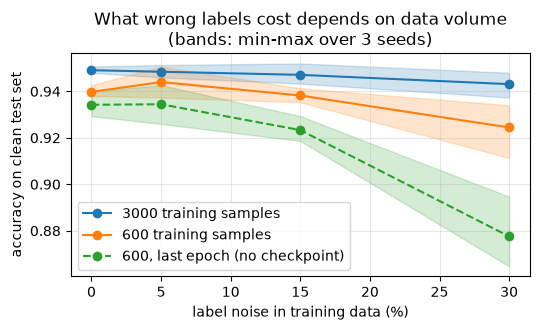

In [12]:
noise_levels = [0.0, 0.05, 0.15, 0.30]
regimes = {"3000 training samples": (3000, True), "600 training samples": (600, True),
           "600, last epoch (no checkpoint)": (600, False)}
sweep = {}                       # regime -> array of shape (noise levels, seeds)
for name, (n, keep) in regimes.items():
    curves = []
    for p in noise_levels:
        accs = []
        for s in [1, 2, 3]:
            data = make_data(n_train=n, label_noise=p, seed=s)
            torch.manual_seed(s)
            model = MLP(width=128, depth=2)
            train_model(model, data, epochs=50, batch_size=128, seed=s, keep_best=keep)
            accs.append(accuracy(model, *data[4:6]))
        curves.append(accs)
        print(f"{name:32s} label noise {p:4.0%}  ->  clean-test accuracy "
              f"{np.mean(accs):.3f}  (seeds span {np.min(accs):.3f}-{np.max(accs):.3f})")
    sweep[name] = np.array(curves)

plt.figure(figsize=(5.5, 3.4))
x = np.array(noise_levels) * 100
for name, curves in sweep.items():
    line, = plt.plot(x, curves.mean(axis=1), "o-" if "no checkpoint" not in name else "o--", label=name)
    plt.fill_between(x, curves.min(axis=1), curves.max(axis=1),
                     color=line.get_color(), alpha=0.2)
plt.xlabel("label noise in training data (%)")
plt.ylabel("accuracy on clean test set")
plt.legend(); plt.grid(alpha=0.3)
plt.title("What wrong labels cost depends on data volume\n(bands: min-max over 3 seeds)")
plt.tight_layout()


With 3000 samples even 30% of random flips costs little (0.949 to 0.943): the flips point in all directions, and the correct majority still pins the class boundaries. With 600 samples, the dashed curve keeps the weights of the last epoch: by then the network has memorized the flipped labels, and 30% of them cost 5.6 points (0.934 to 0.878). The checkpoint cuts that cost to 1.6 points (0.940 to 0.924), because it returns the weights from before the memorizing started. The checkpoint is a defense against wrong labels, not only against overfitting. The shaded bands are the spread over three seeds; read them before trusting any difference between two points.

### 3.2 Wrong labels, with a pattern

Real label errors come from people, and people disagree in patterns. Two simulated geologists split a field area. Each mislabels 30% of their samples, the same rate as the harshest experiment above, but only ever between **adjacent** lithologies on the differentiation axis: granite to andesite, basalt to andesite, andesite to either neighbor. Nobody calls a basalt a granite.

no label errors                 : clean-test accuracy 0.949  (seeds span 0.948-0.951)
30% uniform flips               : clean-test accuracy 0.943  (seeds span 0.937-0.948)
30% adjacent-class disagreement : clean-test accuracy 0.922  (seeds span 0.919-0.927)
               granite  basalt  andesite
true granite      0.97    0.00      0.02
true basalt       0.01    0.90      0.09
true andesite     0.20    0.07      0.73


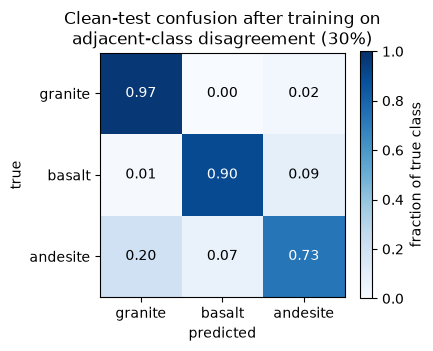

In [13]:
def two_mappers(rate, seed):
    '''Relabeling by two simulated mappers whose errors are only ever between
    adjacent lithologies (granite <-> andesite <-> basalt).'''
    confusion = {
        "A": {"granite": "andesite", "andesite": "granite", "basalt": "andesite"},
        "B": {"granite": "andesite", "andesite": "basalt", "basalt": "andesite"},
    }
    def relabel(frame):
        rng = np.random.default_rng(seed)
        out = frame.copy()
        labels = out["label"].to_numpy().copy()
        is_B = rng.random(len(out)) < 0.5           # who logged each sample
        err = rng.random(len(out)) < rate
        for k in np.where(err)[0]:
            labels[k] = confusion["B" if is_B[k] else "A"][labels[k]]
        out["label"] = labels
        return out
    return relabel

rate = 0.30
adj_accs, confmats = [], []
for s in [1, 2, 3]:
    data = make_data(n_train=3000, relabel=two_mappers(rate, seed=s), seed=s)
    torch.manual_seed(s)
    model = MLP(width=128, depth=2)
    train_model(model, data, epochs=50, batch_size=128, seed=s)
    adj_accs.append(accuracy(model, *data[4:6]))
    model.eval()
    with torch.no_grad():
        pred = model(data[4].to(device)).argmax(1).cpu().numpy()
    confmats.append(confusion_matrix(data[5].numpy(), pred, labels=[0, 1, 2]))

uniform_accs = sweep["3000 training samples"][noise_levels.index(0.30)]
clean_accs = sweep["3000 training samples"][noise_levels.index(0.0)]
for name, accs in [("no label errors", clean_accs),
                   ("30% uniform flips", uniform_accs),
                   ("30% adjacent-class disagreement", adj_accs)]:
    print(f"{name:32s}: clean-test accuracy {np.mean(accs):.3f}  "
          f"(seeds span {np.min(accs):.3f}-{np.max(accs):.3f})")

cm = np.mean(confmats, axis=0)
cm = cm / cm.sum(axis=1, keepdims=True)             # row-normalized (recall)
print(pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=CLASSES).round(2))
fig, ax = plt.subplots(figsize=(4.4, 3.6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES)
ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
for r in range(3):
    for c_ in range(3):
        ax.text(c_, r, f"{cm[r, c_]:.2f}", ha="center", va="center",
                color="white" if cm[r, c_] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Clean-test confusion after training on\nadjacent-class disagreement (30%)")
plt.colorbar(im, ax=ax, label="fraction of true class")
plt.tight_layout()


Same error rate, more than four times the damage, checkpoint included: 30% uniform flips cost 0.6 accuracy points (0.949 to 0.943), 30% adjacent-class disagreement costs 2.7 (0.949 to 0.922), and the seed spans do not overlap. The errors sit on the two boundaries of andesite, the class both mappers argue about: 20% of the true andesites come back granite and 9% of the true basalts come back andesite, while granite and basalt are confused 1% of the time or less.

Every label in a geoscience dataset is an interpretation: a map records what one mapper concluded, a phase pick where one analyst decided the wave arrived. Random errors cancel; errors with a pattern push the same boundary the same way, and more data makes the model more confident in the shared mistake. How often two experts agree on your labels is a ceiling on the accuracy any model can show.

### 3.3 A rare class

Andesite is already rare. We shrink it further and watch the recall of each class, not the overall accuracy.

               overall acc  recall granite  recall basalt  recall andesite
minority kept                                                             
1.00                 0.945           0.972          0.962            0.742
0.50                 0.951           0.984          0.975            0.697
0.20                 0.894           0.985          0.979            0.123
0.05                 0.881           0.985          0.979            0.000


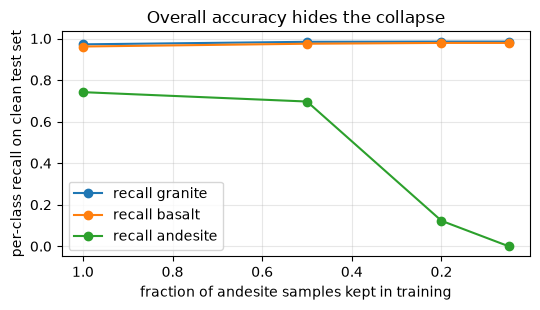

In [14]:
keep_fractions = [1.0, 0.5, 0.2, 0.05]
rows = []
for keep in keep_fractions:
    data = make_data(minority_keep=keep, seed=2)
    torch.manual_seed(2)
    model = MLP(width=32, depth=2)
    train_model(model, data, epochs=25, seed=2)
    Xte, yte = data[4], data[5]
    model.eval()
    with torch.no_grad():
        pred = model(Xte.to(device)).argmax(1).cpu().numpy()
    rec = recall_score(yte.numpy(), pred, average=None, labels=[0, 1, 2])
    rows.append({"minority kept": keep, "overall acc": (pred == yte.numpy()).mean(),
                 **{f"recall {c}": r for c, r in zip(CLASSES, rec)}})

imbalance = pd.DataFrame(rows).set_index("minority kept")
print(imbalance.round(3))

imbalance[[f"recall {c}" for c in CLASSES]].plot(marker="o", figsize=(5.5, 3.2))
plt.xlabel("fraction of andesite samples kept in training")
plt.ylabel("per-class recall on clean test set")
plt.grid(alpha=0.3); plt.gca().invert_xaxis()
plt.title("Overall accuracy hides the collapse")
plt.tight_layout()

Overall accuracy drifts down a few points, nothing alarming on a dashboard. Andesite recall collapses to zero: the model stops predicting the class. In geoscience the rare class is usually the one you care about (the eruption, the induced earthquake, the landslide).

### Your turn (2): weight the rare class

Cross-entropy counts every sample alike, so the many granites dominate the loss. Write `class_weights`, a tensor of three numbers, one per class in the order of `CLASSES`: the number of training samples divided by (3 × the number of samples of that class). Use `torch.bincount(data_rare[1], minlength=3)` for the counts. The cell after it trains with `nn.CrossEntropyLoss(weight=class_weights)` on the 20% case.

In [15]:
data_rare = make_data(minority_keep=0.2, seed=2)
class_weights = None   # your line here

*Answer below (click to open it).*

In [16]:
counts = torch.bincount(data_rare[1], minlength=3)
class_weights = (len(data_rare[1]) / (3 * counts)).float()

In [17]:
print("class weights:", dict(zip(CLASSES, class_weights.numpy().round(2))))
rows = []
for name, crit in [("cross-entropy", None), ("weighted cross-entropy", nn.CrossEntropyLoss(weight=class_weights))]:
    torch.manual_seed(2)
    model = MLP(width=32, depth=2)
    train_model(model, data_rare, epochs=25, seed=2, criterion=crit)
    with torch.no_grad():
        pred = model(data_rare[4]).argmax(1).numpy()
    rec = recall_score(data_rare[5].numpy(), pred, average=None, labels=[0, 1, 2])
    rows.append({"loss": name, "overall acc": (pred == data_rare[5].numpy()).mean(),
                 **{f"recall {c}": r for c, r in zip(CLASSES, rec)}})
print(pd.DataFrame(rows).set_index("loss").round(3))

class weights: {'granite': np.float32(0.56), 'basalt': np.float32(0.87), 'andesite': np.float32(14.96)}


                        overall acc  recall granite  recall basalt  \
loss                                                                 
cross-entropy                 0.894           0.985          0.979   
weighted cross-entropy        0.947           0.960          0.958   

                        recall andesite  
loss                                     
cross-entropy                     0.123  
weighted cross-entropy            0.839  


*Question:* what did the weights buy for andesite, and what did they cost the other two classes? Check that a fix shows up in the recall, not only in the loss.

### 3.4 Mixed sample quality

Half of a geochemistry table from a laboratory XRF with small analytical error, half from a portable field unit several times worse: the metadata usually says which is which. Cross-entropy treats every sample as equally trustworthy. If the variance of each sample is known, weight its loss by $1/\sigma_i^2$, the classification version of weighted least squares. Each training sample draws its noise level from {0.5, 4.0} standard deviations; the same model trains once without the weights and once with them.

In [18]:
mix = (0.5, 4.0)          # each training sample: lab-grade or field-grade noise


def train_weighted(model, data, weights, epochs=25, lr=1e-3, batch_size=256, seed=0):
    '''Minibatch training with a per-sample weight inside the cross-entropy.'''
    Xtr, ytr = data[0], data[1]
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    per_sample = nn.CrossEntropyLoss(reduction="none")
    g = torch.Generator().manual_seed(seed)
    n = len(Xtr)
    for _ in range(epochs):
        model.train()
        for i in range(0, n, batch_size):
            idx = torch.randperm(n, generator=g)[:batch_size]
            opt.zero_grad()
            loss = (per_sample(model(Xtr[idx].to(device)), ytr[idx].to(device))
                    * weights[idx].to(device)).mean()
            loss.backward()
            opt.step()


hetero_accs = {}
for scheme in ["ignore the metadata", "inverse-variance weights"]:
    accs = []
    for s in [1, 2, 3]:
        *data6, sigma = make_data(n_train=3000, hetero_sigma=mix, seed=s)
        w = 1.0 / sigma**2
        w = w / w.mean()                     # normalize so the lr keeps its meaning
        torch.manual_seed(s)
        model = MLP(width=64, depth=2)
        if scheme == "ignore the metadata":
            train_model(model, tuple(data6), epochs=25, seed=s)
        else:
            train_weighted(model, tuple(data6), w, epochs=25, seed=s)
        accs.append(accuracy(model, *data6[4:6]))
    hetero_accs[scheme] = accs
    print(f"{scheme:26s}: clean-test accuracy {np.mean(accs):.3f}  "
          f"(seeds span {np.min(accs):.3f}-{np.max(accs):.3f})")
data_lab = make_data(feature_noise=0.0, seed=3)            # every sample lab-grade
torch.manual_seed(3)
model = MLP(width=64, depth=2)
train_model(model, data_lab, epochs=25, seed=3)
print(f"{'all lab-grade (reference)':26s}: clean-test accuracy {accuracy(model, *data_lab[4:6]):.3f}")

ignore the metadata       : clean-test accuracy 0.936  (seeds span 0.934-0.937)


inverse-variance weights  : clean-test accuracy 0.946  (seeds span 0.939-0.951)


all lab-grade (reference) : clean-test accuracy 0.949


The mixed table costs 1.3 points against the all-lab-grade reference (0.936 against 0.949). Giving the model the variance it already had in the metadata recovers 1.0 of them (0.946), with no new data and one line of loss code. Any column named `uncertainty`, `std_err`, `quality` or `pick_weight` is an invitation to weight the loss; most pipelines drop it at ingest.

### 3.5 How much data is enough?

The learning curve: test accuracy against the number of training samples. It answers "would more data help?" with a measurement.

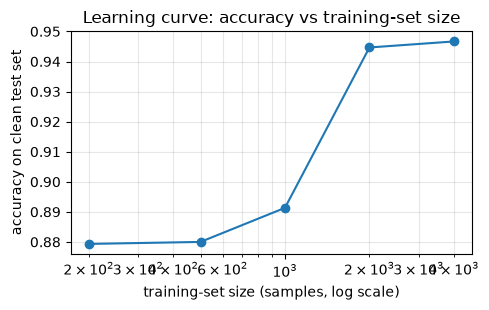

In [19]:
def plot_learning_curves(sizes, width=32, depth=2, epochs=25, seed=4):
    '''Test accuracy as a function of training-set size (Pillar 1 diagnostic).'''
    accs = []
    for n in sizes:
        data = make_data(n_train=n, seed=seed)
        torch.manual_seed(seed)
        model = MLP(width=width, depth=depth)
        train_model(model, data, epochs=epochs, seed=seed)
        accs.append(accuracy(model, *data[4:6]))
    plt.figure(figsize=(5, 3.2))
    plt.semilogx(sizes, accs, "o-")
    plt.xlabel("training-set size (samples, log scale)")
    plt.ylabel("accuracy on clean test set")
    plt.grid(alpha=0.3, which="both")
    plt.title("Learning curve: accuracy vs training-set size")
    plt.tight_layout()
    return accs

sizes = [200, 500, 1000, 2000, 4000]
accs_vs_size = plot_learning_curves(sizes)

The curve rises steeply, then flattens. If it is still rising at your data size, collect more before tuning anything else. If it has flattened, more of the same data will not help; better labels or better features might.

**Write your rules** for station 1 (section 8).

```{admonition} Checkpoint: end of session I
:class: tip
Stop here on Wednesday. On Monday, restart the kernel, run sections 1 and 2 (a few seconds), and continue from section 4.
```

## 4. Station 2: the architecture

Same clean data (the reference dataset of section 2), different models.

### 4.1 Width

*Prediction:* from 4 to 256 units per layer, where does the test accuracy stop improving?

   width  params  test acc
0      4      75  0.850667
1     16     483  0.882667
2     64    4995  0.952667
3    256   69123  0.950000


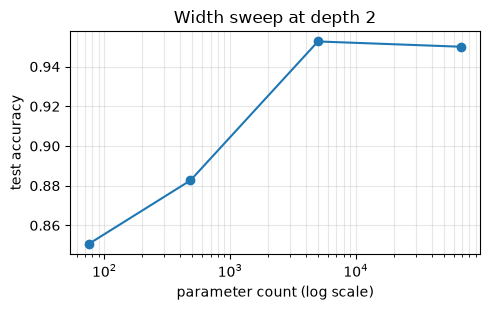

In [20]:
data = make_data(seed=5)

widths = [4, 16, 64, 256]
rows = []
for w in widths:
    torch.manual_seed(5)
    model = MLP(width=w, depth=2)
    train_model(model, data, epochs=25, seed=5)
    rows.append({"width": w, "params": count_params(model),
                 "test acc": accuracy(model, *data[4:6])})
width_sweep = pd.DataFrame(rows)
print(width_sweep)

plt.figure(figsize=(5, 3.2))
plt.semilogx(width_sweep["params"], width_sweep["test acc"], "o-")
plt.xlabel("parameter count (log scale)")
plt.ylabel("test accuracy")
plt.grid(alpha=0.3, which="both"); plt.title("Width sweep at depth 2")
plt.tight_layout()

Accuracy saturates within a factor of a few of the smallest adequate width. Past that point, weights cost training time, memory and, on small datasets, overfitting, and buy no accuracy.

### 4.2 Depth at a fixed number of weights

Spend about 5,000 weights on 1, 2 or 4 hidden layers.

In [21]:
def width_for_budget(depth, budget=5000):
    '''Smallest width whose MLP meets or exceeds the parameter budget.'''
    for w in range(1, 1024):
        if count_params(MLP(width=w, depth=depth)) >= budget:
            return w
    return 1024

rows = []
for d in [1, 2, 4]:
    w = width_for_budget(d)
    torch.manual_seed(6)
    model = MLP(width=w, depth=d)
    train_model(model, data, epochs=25, seed=6)
    rows.append({"depth": d, "width": w, "params": count_params(model),
                 "test acc": accuracy(model, *data[4:6])})
depth_sweep = pd.DataFrame(rows)
print(depth_sweep)

   depth  width  params  test acc
0      1    385    5008  0.954000
1      2     65    5138  0.953333
2      4     39    5190  0.945333


On nine features, depth buys little: the structure the generator planted is simple, and a shallow, wide network represents it as well as a deep one. Depth pays when the data are built of parts of parts: edges, textures and objects in images (4.3), samples, motifs and phrases in sequences (4.4).

**Write your rule** for station 2 (section 8).

## 5. Station 3: training

Same data, same architecture; only the way we train changes.

### 5.1 Starting weights

Notebook 4.0 started from random weights drawn with a seed, never from zeros. Test it.

*Prediction:* with every weight and bias at zero, what is the validation accuracy after 25 epochs? With the default random weights multiplied by 10?

### Your turn (3): two ways to start

Write `init_scaled(model, factor)`: inside `with torch.no_grad():`, loop over `model.parameters()` and multiply each one by `factor` in place (`p.mul_(factor)`). A factor of 0 sets every weight to zero.

In [22]:
def init_scaled(model, factor):
    pass   # your lines here

*Answer below (click to open it).*

In [23]:
def init_scaled(model, factor):
    with torch.no_grad():
        for p in model.parameters():
            p.mul_(factor)

random (default)  validation accuracy 0.938  (seeds 0.937, 0.939)


all zeros         validation accuracy 0.560  (seeds 0.560, 0.560)


random x 10       validation accuracy 0.817  (seeds 0.821, 0.813)


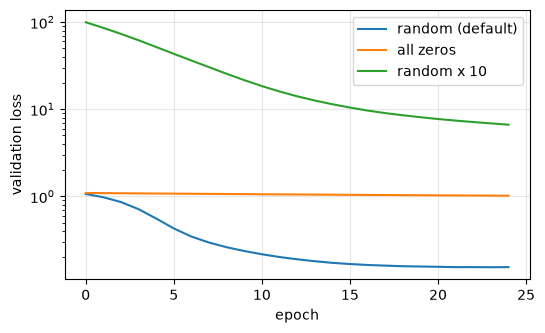

In [24]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for factor, label in [(1.0, "random (default)"), (0.0, "all zeros"), (10.0, "random x 10")]:
    accs = []
    for s in [1, 2]:
        torch.manual_seed(s)
        model = MLP(width=32, depth=2)
        init_scaled(model, factor)
        h = train_model(model, data, epochs=25, seed=s)
        accs.append(h["val_acc"][-1])
    ax.plot(h["val_loss"], label=label)
    print(f"{label:17s} validation accuracy {np.mean(accs):.3f}  (seeds {accs[0]:.3f}, {accs[1]:.3f})")
ax.set_xlabel("epoch"); ax.set_ylabel("validation loss"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=0.3)

*Questions.* With zero starting weights, every hidden unit computes the same thing and receives the same gradient: why does it never stop being identical to its neighbors? What fraction of the samples is granite, and how does that compare with the zero-start accuracy?

### 5.2 The learning rate

Three runs that differ only in the learning rate.

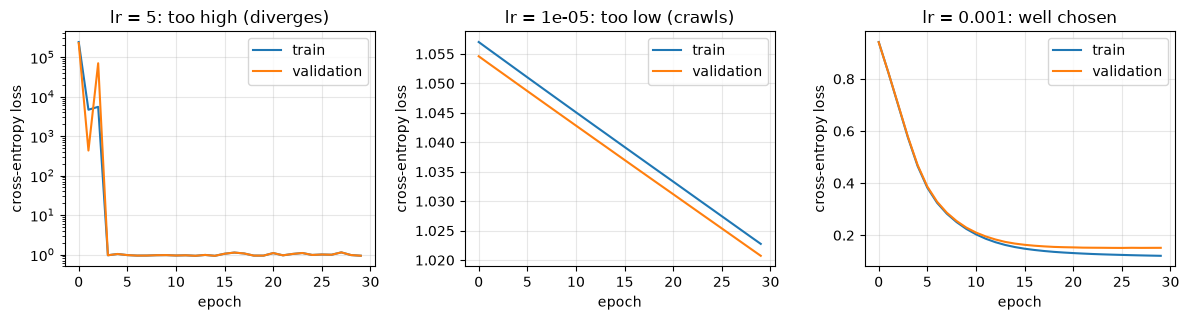

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharex=True)
for ax, (lr, label) in zip(axes, [(5.0, "too high (diverges)"),
                                  (1e-5, "too low (crawls)"),
                                  (1e-3, "well chosen")]):
    torch.manual_seed(8)
    model = MLP(width=32, depth=2)
    hist = train_model(model, data, epochs=30, lr=lr, optimizer="sgd"
                       if lr == 5.0 else "adam", seed=8)
    plot_history(hist, ax=ax, title=f"lr = {lr:g}: {label}", logy=(lr == 5.0))
plt.tight_layout()

Three signatures to memorize:

* **Too high**: the loss oscillates or explodes (log axis); each step overshoots the valley.
* **Too low**: both curves creep down a nearly straight line; training "works" but would need hundreds of epochs.
* **Well chosen**: a fast early drop, then a smooth flattening.

Sweep the learning rate in powers of 10 first; nothing else in this station matters until it is roughly right.

### 5.3 Batch size

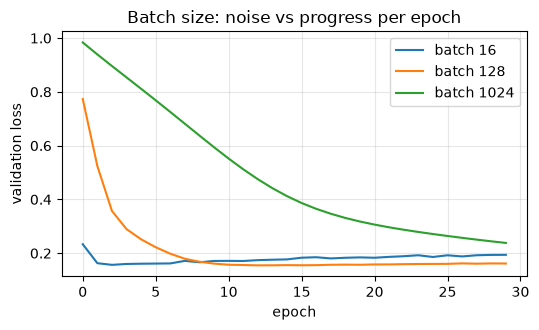

In [26]:
plt.figure(figsize=(5.5, 3.4))
for bs in [16, 128, 1024]:
    torch.manual_seed(9)
    model = MLP(width=32, depth=2)
    hist = train_model(model, data, epochs=30, batch_size=bs, seed=9)
    plt.plot(hist["val_loss"], label=f"batch {bs}")
plt.xlabel("epoch"); plt.ylabel("validation loss")
plt.legend(); plt.grid(alpha=0.3)
plt.title("Batch size: noise vs progress per epoch")
plt.tight_layout()

Small batches take many noisy steps per epoch: fast progress per epoch, with jitter. Large batches take few smooth steps, so at a fixed number of epochs their curve lags. Compare at an equal number of updates before concluding that one batch size is better. In practice the batch is the largest that fits comfortably in memory, with the learning rate tuned again when the batch changes.

### 5.4 Overfitting, and when to stop

A large model, a small noisy training set, and a long run.

val loss at best epoch 16: 0.380
val loss at final epoch:  1.349
validation accuracy, weights of the last epoch: 0.850
validation accuracy, weights returned (epoch 16): 0.900


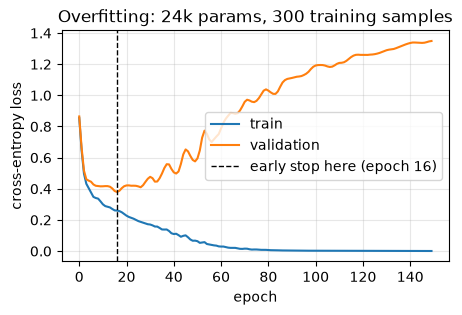

In [27]:
small_noisy = make_data(n_train=400, label_noise=0.10, seed=10)
torch.manual_seed(10)
big_model = MLP(width=256, depth=3)
hist_over = train_model(big_model, small_noisy, epochs=150, seed=10)   # keep_best=True: the checkpoint

best_epoch = int(np.argmin(hist_over["val_loss"]))
ax = plot_history(hist_over, title="Overfitting: 24k params, 300 training samples")
ax.axvline(best_epoch, color="k", ls="--", lw=1,
           label=f"early stop here (epoch {best_epoch})")
ax.legend()
print(f"val loss at best epoch {best_epoch}: {hist_over['val_loss'][best_epoch]:.3f}")
print(f"val loss at final epoch:  {hist_over['val_loss'][-1]:.3f}")
print(f"validation accuracy, weights of the last epoch: {hist_over['val_acc'][-1]:.3f}")
print(f"validation accuracy, weights returned (epoch {hist_over['best_epoch']}): "
      f"{accuracy(big_model, small_noisy[2], small_noisy[3]):.3f}")

The training loss falls toward zero while the validation loss reaches a minimum and climbs. The checkpoint in `train_model` (section 2.4) already keeps the weights of the epoch with the lowest validation loss, so the model it returns is the one at the dashed line, not the one at epoch 150. **Early stopping** goes one step further: stop the run when the validation loss has not improved for a set number of epochs (the patience), and save the time of the remaining epochs.

**Write your rule** for station 3 (section 8).

## 6. Station 4: how much to trust a prediction

### 6.1 Deep ensembles: uncertainty from disagreement

Train the same architecture from five seeds. The runs agree on easy samples and disagree near class boundaries, and that disagreement is an uncertainty estimate (Lakshminarayanan et al., 2017). Two separate questions: does disagreement **rank** samples by their risk of error (discrimination), and when the ensemble says 80%, is it right 80% of the time (calibration)?

In [28]:
n_members = 5
member_probs, member_accs = [], []
Xte, yte = data[4], data[5]
for s in range(n_members):
    torch.manual_seed(100 + s)                  # different init per member
    member = MLP(width=64, depth=2)
    train_model(member, data, epochs=25, seed=100 + s)  # different batches too
    member.eval()
    with torch.no_grad():
        probs = torch.softmax(member(Xte.to(device)), dim=1).cpu().numpy()
    member_probs.append(probs)
    member_accs.append(accuracy(member, Xte, yte))

member_probs = np.stack(member_probs)           # (members, samples, classes)
ens_mean = member_probs.mean(axis=0)
ens_pred = ens_mean.argmax(1)
ens_acc = (ens_pred == yte.numpy()).mean()
# disagreement: std across members of the probability of the ensemble's chosen class
ens_std = member_probs.std(axis=0)[np.arange(len(yte)), ens_pred]

print("member accuracies:", np.round(member_accs, 3))
print(f"ensemble-mean accuracy: {ens_acc:.3f}")

member accuracies: [0.951 0.951 0.951 0.951 0.951]
ensemble-mean accuracy: 0.952


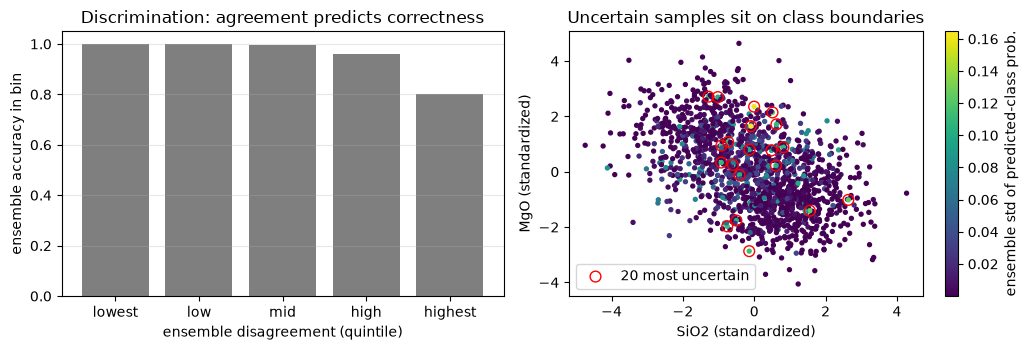

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))

# discrimination check: accuracy within quintiles of ensemble disagreement
bins = np.quantile(ens_std, np.linspace(0, 1, 6))
bin_idx = np.clip(np.digitize(ens_std, bins[1:-1]), 0, 4)
correct = ens_pred == yte.numpy()
bin_acc = [correct[bin_idx == b].mean() for b in range(5)]
ax[0].bar(range(5), bin_acc, color="tab:gray")
ax[0].set_xticks(range(5))
ax[0].set_xticklabels(["lowest", "low", "mid", "high", "highest"])
ax[0].set_xlabel("ensemble disagreement (quintile)")
ax[0].set_ylabel("ensemble accuracy in bin")
ax[0].set_title("Discrimination: agreement predicts correctness")
ax[0].grid(alpha=0.3, axis="y")

# where the uncertain samples live in feature space
sio2 = Xte[:, FEATURES.index("SIO2")].numpy()
mgo = Xte[:, FEATURES.index("MGO")].numpy()
sc = ax[1].scatter(sio2, mgo, c=ens_std, s=8, cmap="viridis")
flag = np.argsort(ens_std)[-20:]                # 20 most uncertain samples
ax[1].scatter(sio2[flag], mgo[flag], facecolors="none",
              edgecolors="red", s=60, label="20 most uncertain")
plt.colorbar(sc, ax=ax[1], label="ensemble std of predicted-class prob.")
ax[1].set_xlabel("SiO2 (standardized)"); ax[1].set_ylabel("MgO (standardized)")
ax[1].set_title("Uncertain samples sit on class boundaries")
ax[1].legend()
plt.tight_layout()

The samples where the members disagree are the ones the ensemble gets wrong most often, and they sit on class boundaries. In a workflow you would send them to an analyst. This is discrimination: only the order matters.

### 6.2 Calibration

Calibration asks whether the probability itself is right. The reliability diagram bins samples by stated confidence and plots the observed accuracy in each bin; the **expected calibration error** (ECE) is the average gap, weighted by the number of samples per bin. With three classes, the confidence of the predicted class lies between 1/3 and 1.

single member    accuracy 0.951   ECE 0.010
ensemble mean    accuracy 0.952   ECE 0.010


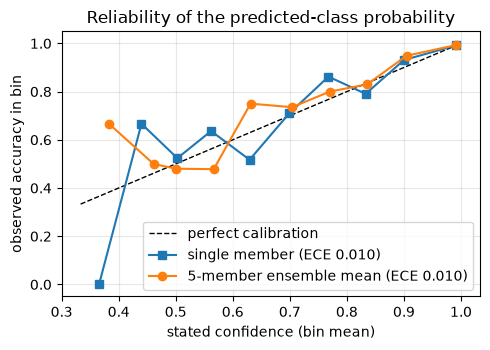

In [30]:
def reliability(probs, y_true, n_bins=10):
    '''Top-label reliability: bin samples by predicted-class confidence.
    Returns per-bin mean confidence, per-bin accuracy, counts, and ECE.'''
    conf = probs.max(axis=1)
    correct = probs.argmax(axis=1) == y_true
    edges = np.linspace(1 / 3, 1.0, n_bins + 1)     # 3 classes: confidence >= 1/3
    idx = np.clip(np.digitize(conf, edges[1:-1]), 0, n_bins - 1)
    counts = np.bincount(idx, minlength=n_bins)
    bin_conf = np.array([conf[idx == b].mean() if counts[b] else np.nan
                         for b in range(n_bins)])
    bin_acc = np.array([correct[idx == b].mean() if counts[b] else np.nan
                        for b in range(n_bins)])
    ok = counts > 0
    ece = np.sum(np.abs(bin_acc[ok] - bin_conf[ok]) * counts[ok]) / counts.sum()
    return bin_conf, bin_acc, counts, ece


y_np = yte.numpy()
bc_s, ba_s, _, ece_single = reliability(member_probs[0], y_np)
bc_e, ba_e, _, ece_ens = reliability(ens_mean, y_np)

plt.figure(figsize=(5, 3.6))
plt.plot([1 / 3, 1], [1 / 3, 1], "k--", lw=1, label="perfect calibration")
plt.plot(bc_s, ba_s, "s-", label=f"single member (ECE {ece_single:.3f})")
plt.plot(bc_e, ba_e, "o-", label=f"5-member ensemble mean (ECE {ece_ens:.3f})")
plt.xlabel("stated confidence (bin mean)")
plt.ylabel("observed accuracy in bin")
plt.legend(); plt.grid(alpha=0.3)
plt.title("Reliability of the predicted-class probability")
plt.tight_layout()

print(f"single member    accuracy {(member_probs[0].argmax(1) == y_np).mean():.3f}"
      f"   ECE {ece_single:.3f}")
print(f"ensemble mean    accuracy {ens_acc:.3f}   ECE {ece_ens:.3f}")


Here a single member is already nearly calibrated (ECE 0.010) and the ensemble mean gains nothing measurable (0.010). Deep ensembles improve calibration on large networks, especially under distribution shift; a two-layer network on nine features is not miscalibrated enough to fix. "Well calibrated" is a number you attach to a model after running this cell, not a property of a method.

### 6.3 MC dropout: an uncertainty estimate from one model

Five training runs are expensive when one run takes a week. **Monte Carlo dropout** trains one network with dropout, then leaves dropout **on** at prediction time and runs each sample through it $T = 50$ times (Gal & Ghahramani, 2016). The mean of the passes is the prediction; their spread is the uncertainty.

In [31]:
torch.manual_seed(150)
mc_model = MLP(width=64, depth=2, dropout=0.2)
train_model(mc_model, data, epochs=25, seed=150)

T = 50
torch.manual_seed(151)             # fixes which units drop in each pass
mc_model.train()                   # dropout stays ACTIVE at prediction time
with torch.no_grad():
    mc_probs = np.stack([
        torch.softmax(mc_model(Xte.to(device)), dim=1).cpu().numpy()
        for _ in range(T)])
mc_model.eval()

mc_mean = mc_probs.mean(axis=0)
mc_pred = mc_mean.argmax(1)
mc_acc = (mc_pred == y_np).mean()
mc_std = mc_probs.std(axis=0)[np.arange(len(yte)), mc_pred]
bc_m, ba_m, _, ece_mc = reliability(mc_mean, y_np)

head_to_head = pd.DataFrame({
    "deep ensemble (5 members)": {"test accuracy": round(ens_acc, 3),
                                  "ECE": round(ece_ens, 3),
                                  "models trained": 5, "prediction passes": 5},
    f"MC dropout (T={T})": {"test accuracy": round(mc_acc, 3),
                            "ECE": round(ece_mc, 3),
                            "models trained": 1, "prediction passes": T},
}).T
print(head_to_head)


                           test accuracy    ECE  models trained  \
deep ensemble (5 members)          0.952  0.010             5.0   
MC dropout (T=50)                  0.953  0.017             1.0   

                           prediction passes  
deep ensemble (5 members)                5.0  
MC dropout (T=50)                       50.0  


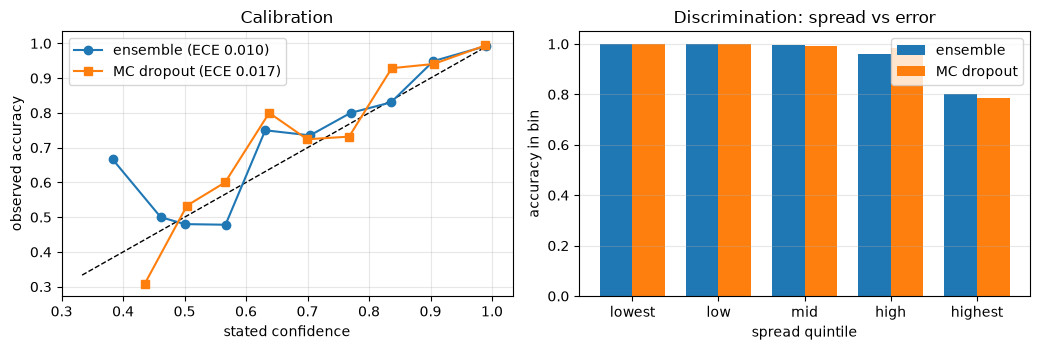

In [32]:
def quintile_accuracy(spread, pred, y_true):
    '''Accuracy within quintiles of an uncertainty score (discrimination).'''
    edges = np.quantile(spread, np.linspace(0, 1, 6))
    idx = np.clip(np.digitize(spread, edges[1:-1]), 0, 4)
    correct = pred == y_true
    return [correct[idx == b].mean() for b in range(5)]


fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].plot([1 / 3, 1], [1 / 3, 1], "k--", lw=1)
ax[0].plot(bc_e, ba_e, "o-", label=f"ensemble (ECE {ece_ens:.3f})")
ax[0].plot(bc_m, ba_m, "s-", label=f"MC dropout (ECE {ece_mc:.3f})")
ax[0].set_xlabel("stated confidence"); ax[0].set_ylabel("observed accuracy")
ax[0].set_title("Calibration"); ax[0].legend(); ax[0].grid(alpha=0.3)

xq = np.arange(5)
ax[1].bar(xq - 0.19, quintile_accuracy(ens_std, ens_pred, y_np), 0.38,
          label="ensemble")
ax[1].bar(xq + 0.19, quintile_accuracy(mc_std, mc_pred, y_np), 0.38,
          label="MC dropout")
ax[1].set_xticks(xq)
ax[1].set_xticklabels(["lowest", "low", "mid", "high", "highest"])
ax[1].set_xlabel("spread quintile"); ax[1].set_ylabel("accuracy in bin")
ax[1].set_title("Discrimination: spread vs error")
ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout()


One dropout model matches the five-member ensemble on accuracy (0.953 against 0.952, inside the spread between seeds) and on discrimination, for one training run instead of five. Its calibration is a little worse (ECE 0.017 against 0.010).

### 6.4 Out of range

Every score so far assumed the test samples come from the same ranges as the training samples: the model **interpolates**. Deployment breaks this: the mapped area ends, the next pluton is more evolved than anything in the survey. Predicting there is **extrapolation**. We train an ensemble only on samples within one standard deviation of each unit's typical composition (the field campaign mapped only typical rocks), then test on a fresh draw over the full range.

In [33]:
def diff_index(frame, stats=None):
    '''Per-class standardized SiO2: observable proxy for the latent
    differentiation index, the generator parameter we bound.'''
    if stats is None:
        stats = frame.groupby("label")["SIO2"].agg(["mean", "std"])
    mu = frame["label"].map(stats["mean"]).to_numpy()
    sd = frame["label"].map(stats["std"]).to_numpy()
    return (frame["SIO2"].to_numpy() - mu) / sd, stats


train_frame = mlgeo_synth.geochem_table(n=4000, seed=40)
z_train, z_stats = diff_index(train_frame)
bounded = train_frame[np.abs(z_train) <= 1.0]        # the "mapped" range
print(f"training keeps {len(bounded)} of {len(train_frame)} samples "
      "(|z| <= 1: the central ~68% of each unit's compositional range)")

test_frame = mlgeo_synth.geochem_table(n=3000, seed=41)   # fresh draw, FULL range
z_test, _ = diff_index(test_frame, z_stats)

Xb, yb = table_to_xy(bounded)
Xtr_b, Xva_b, ytr_b, yva_b = train_test_split(Xb, yb, test_size=0.25,
                                              random_state=40, stratify=yb)
Xte_f, yte_f = table_to_xy(test_frame)
scaler_b = StandardScaler().fit(Xtr_b)
Xtr_b, Xva_b, Xte_f = (scaler_b.transform(a) for a in (Xtr_b, Xva_b, Xte_f))
rngs = [np.random.default_rng(4000 + k) for k in range(3)]
Xtr_b, Xva_b, Xte_f = (a + r.normal(0, 1, a.shape)   # the usual 1-sigma noise floor
                       for a, r in zip((Xtr_b, Xva_b, Xte_f), rngs))
t32 = lambda a: torch.as_tensor(np.ascontiguousarray(a), dtype=torch.float32)
data_b = (t32(Xtr_b), torch.as_tensor(ytr_b), t32(Xva_b), torch.as_tensor(yva_b),
          t32(Xte_f), torch.as_tensor(yte_f))

ood_probs = []
for s in range(5):
    torch.manual_seed(200 + s)
    member = MLP(width=64, depth=2)
    train_model(member, data_b, epochs=25, seed=200 + s)
    member.eval()
    with torch.no_grad():
        ood_probs.append(torch.softmax(member(data_b[4].to(device)),
                                       dim=1).cpu().numpy())
ood_probs = np.stack(ood_probs)
ood_mean = ood_probs.mean(axis=0)
ood_pred = ood_mean.argmax(1)
ood_correct = ood_pred == yte_f
ood_std = ood_probs.std(axis=0)[np.arange(len(yte_f)), ood_pred]


training keeps 2723 of 4000 samples (|z| <= 1: the central ~68% of each unit's compositional range)


                                      n  error rate  mean disagreement
range                                                                 
in range (|z| <= 1)                2046       0.050              0.011
near extrapolation (1 < |z| <= 2)   824       0.076              0.015
far extrapolation (|z| > 2)         130       0.085              0.019

out-of-range errors: 74 on 954 out-of-range samples
silent failures (wrong AND disagreement at or below the in-range median): 1 of 74 (1% of out-of-range errors)


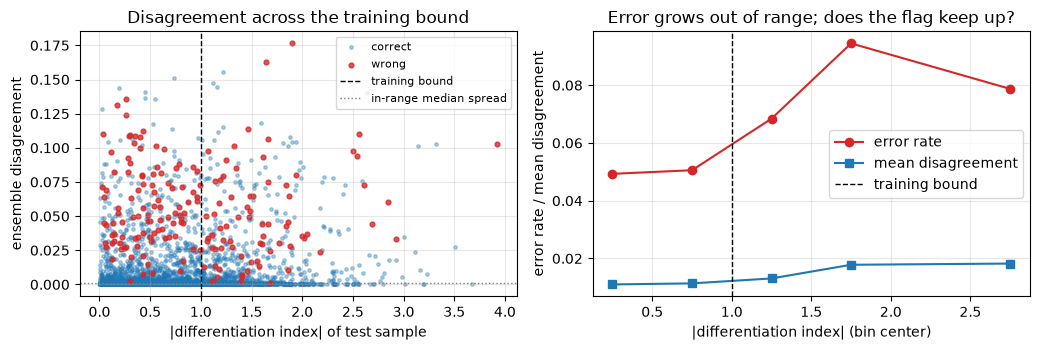

In [34]:
abs_z = np.abs(z_test)
groups = {"in range (|z| <= 1)": abs_z <= 1.0,
          "near extrapolation (1 < |z| <= 2)": (abs_z > 1.0) & (abs_z <= 2.0),
          "far extrapolation (|z| > 2)": abs_z > 2.0}
ood_table = pd.DataFrame(
    [{"range": g, "n": int(m.sum()),
      "error rate": 1 - ood_correct[m].mean(),
      "mean disagreement": ood_std[m].mean()} for g, m in groups.items()]
).set_index("range")
print(ood_table.round(3))

in_med = np.median(ood_std[groups["in range (|z| <= 1)"]])
wrong_ood = (abs_z > 1.0) & ~ood_correct
silent = wrong_ood & (ood_std <= in_med)     # wrong, yet looks as calm as in-range
print(f"\nout-of-range errors: {wrong_ood.sum()} on {int((abs_z > 1).sum())} "
      "out-of-range samples")
print(f"silent failures (wrong AND disagreement at or below the in-range median): "
      f"{silent.sum()} of {wrong_ood.sum()} "
      f"({silent.sum() / max(wrong_ood.sum(), 1):.0%} of out-of-range errors)")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].scatter(abs_z[ood_correct], ood_std[ood_correct], s=6, alpha=0.35,
              label="correct")
ax[0].scatter(abs_z[~ood_correct], ood_std[~ood_correct], s=12, alpha=0.8,
              color="tab:red", label="wrong")
ax[0].axvline(1.0, color="k", ls="--", lw=1, label="training bound")
ax[0].axhline(in_med, color="tab:gray", ls=":", lw=1,
              label="in-range median spread")
ax[0].set_xlabel("|differentiation index| of test sample")
ax[0].set_ylabel("ensemble disagreement")
ax[0].set_title("Disagreement across the training bound")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

edges = [0, 0.5, 1.0, 1.5, 2.0, 3.5]
centers, err_b, dis_b = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (abs_z >= lo) & (abs_z < hi)
    if m.sum() < 10:
        continue
    centers.append((lo + hi) / 2)
    err_b.append(1 - ood_correct[m].mean())
    dis_b.append(ood_std[m].mean())
ax[1].plot(centers, err_b, "o-", color="tab:red", label="error rate")
ax[1].plot(centers, dis_b, "s-", color="tab:blue", label="mean disagreement")
ax[1].axvline(1.0, color="k", ls="--", lw=1, label="training bound")
ax[1].set_xlabel("|differentiation index| (bin center)")
ax[1].set_ylabel("error rate / mean disagreement")
ax[1].set_title("Error grows out of range; does the flag keep up?")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()


The error rate rises by more than half across the training bound: 5.0% in range, 7.6% just past it, 8.5% beyond two units. Mean disagreement rises with it. Of the 74 errors out of range, one is a **silent failure**: wrong, yet with disagreement at or below the in-range median. Its composition landed in a neighboring class's familiar territory, so all five members agreed on the same wrong label. Disagreement flags unfamiliar regions of feature space; it cannot flag a sample that came to look familiar.

The in-range and out-of-range disagreements also overlap heavily: no threshold on the spread recovers the training bound. The bound is metadata only you have. State the ranges your training data covered next to every score you report.

**Write your rule** for station 4 (section 8).

## 7. Six broken training runs

Six runs, each broken in a different way. The pathologies, in shuffled order: learning rate too high, learning rate too low, overfitting, underfitting, heavy label noise, and validation data easier than the training data (the signature of leakage). For each run write the pathology, the evidence in the curves, and the first fix you would try, **before** reading the code or opening the solution.

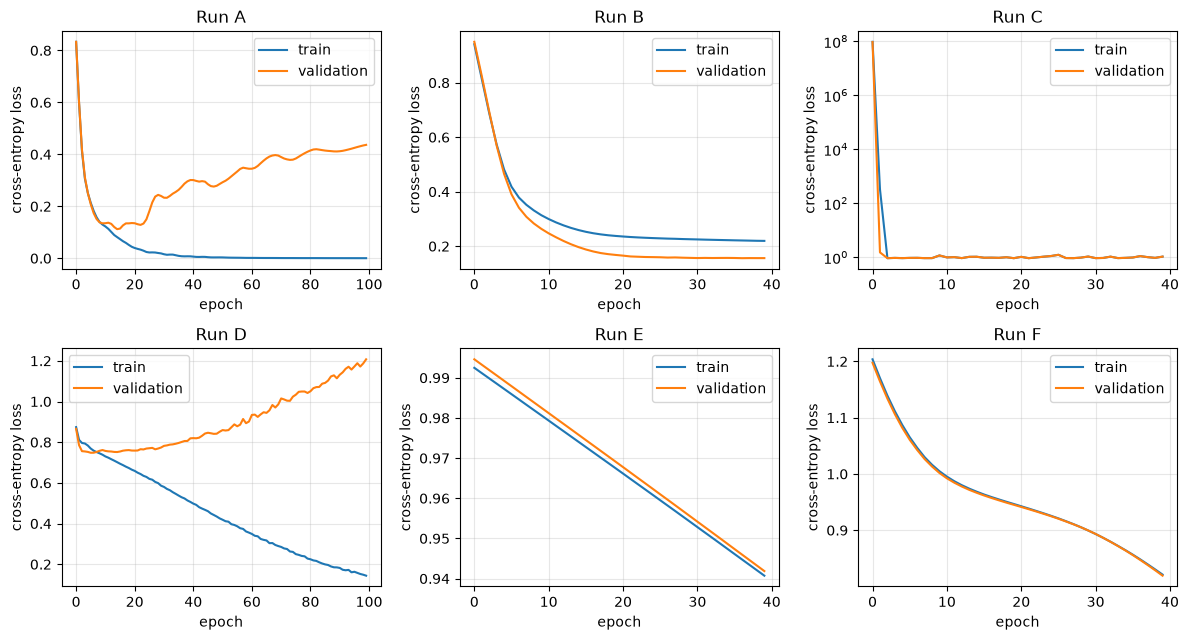

In [35]:
def make_broken_runs():
    '''Six rigged training runs. Diagnose from the curves before reading this.'''
    runs = {}
    d = make_data(seed=20)
    torch.manual_seed(20)
    runs["high_lr"] = train_model(MLP(32, 2), d, epochs=40, lr=5.0,
                                  optimizer="sgd", seed=20)
    torch.manual_seed(21)
    runs["low_lr"] = train_model(MLP(32, 2), d, epochs=40, lr=1e-5, seed=21)
    torch.manual_seed(22)
    runs["overfit"] = train_model(MLP(256, 3), make_data(n_train=400, seed=22),
                                  epochs=100, seed=22)
    torch.manual_seed(23)
    runs["underfit"] = train_model(MLP(1, 1), d, epochs=40, seed=23)   # width-1 bottleneck
    torch.manual_seed(24)
    runs["label_noise"] = train_model(MLP(256, 2),
                                      make_data(n_train=800, label_noise=0.35, seed=24),
                                      epochs=100, seed=24)
    # leakage-style pathology: training inputs get heavy augmentation noise,
    # validation stays pristine -> validation beats training throughout
    d_leak = list(make_data(seed=25))
    rng = np.random.default_rng(25)
    d_leak[0] = d_leak[0] + torch.as_tensor(
        rng.normal(0, 0.8, d_leak[0].shape), dtype=torch.float32)
    torch.manual_seed(25)
    runs["leakage"] = train_model(MLP(32, 2), tuple(d_leak), epochs=40, seed=25)
    return runs

broken = make_broken_runs()
display_order = ["overfit", "leakage", "high_lr", "label_noise", "low_lr", "underfit"]
letters = "ABCDEF"

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, letter, key in zip(axes.ravel(), letters, display_order):
    plot_history(broken[key], ax=ax, title=f"Run {letter}",
                 logy=(max(broken[key]["train_loss"]) > 10))
plt.tight_layout()

```{admonition} Solution
:class: dropdown

**Run A — overfitting.** Training loss falls toward zero while validation loss bottoms out early and climbs steadily. A 24k-parameter model saw only 300 training samples. Fix: more data, a smaller model, regularization, or early stopping at the validation minimum.

**Run B — data leakage (or train-only augmentation).** Validation loss sits *below* training loss for the whole run. Genuine validation data is never systematically easier than training data; when validation wins, suspect that validation samples leaked into training, that the split duplicated near-identical samples across the boundary, or that noise/augmentation was applied to the training inputs only (the actual cause here). Fix: audit the split before believing the numbers.

**Run C — learning rate too high.** The loss explodes within a few epochs (note the log axis) instead of decreasing. Steps overshoot the minimum and diverge. Fix: drop the learning rate by 10x-100x and re-run.

**Run D — heavy label noise.** Training loss keeps sinking as the oversized model memorizes flipped labels, while validation loss quickly reaches a floor and stays there — it plateaus rather than climbing sharply, and validation accuracy is capped far below what the features support. Distinguishing this from overfitting takes care: with label noise, no amount of regularization raises the validation ceiling. Fix: audit and clean the labels (section 3.1).

**Run E — learning rate too low.** Both curves descend a shallow, nearly straight line and are still far from converged after 40 epochs. Nothing is wrong except patience. Fix: raise the learning rate by 10x-100x.

**Run F — underfitting.** Both curves plateau almost immediately at a high loss with a tiny train-validation gap. The width-1 network cannot represent the class boundaries. Fix: increase capacity (width/depth) or engineer better features.
```

## 8. Your rules

One rule per station, in the format of the class rubric (section 9 and [The rubric](mlgeo_4.7_dl_rubric.md)): what to do, how someone else checks it, and the number from your run that justifies it.

| Station | Rule (what to do) | Check (how someone else verifies it) | Evidence (your number, with seeds) |
|---|---|---|---|
| 1 data | | | |
| 2 architecture | | | |
| 3 training | | | |
| 4 trust | | | |

Example: *"Report the recall of every class, not the accuracy. Check: the table of recall per class in the results. Evidence: with 5% of the andesites kept, accuracy 0.881 while andesite recall is 0.000."*

## 9. The rubric

The checklist of this section is the companion page [The rubric](mlgeo_4.7_dl_rubric.md). Every item has an identifier, a check, and the evidence that shows it passed; coding agents read the same page as their specification. Its six sections:

- **A. Framing, before any model.** Name the data sample, the input, the quantity to predict and how the model will be used, split along that deployment axis, and compute baselines without learning.
- **B. Choosing the network from the structure of the data.** A table of features, a grid, a sequence in time or a set of linked stations each calls for the layer whose assumption matches it.
- **C. Design checks, by network.** The checks specific to each kind of network of this chapter, such as the receptive field of a convolution against the physical scale of the pattern, or causal input windows for a recurrent network.
- **D. Training.** Random starting weights with a recorded seed, a loss that fits the errors, both loss curves at every epoch, at least three seeds, and the test set used once.
- **E. Evaluation.** Errors in physical units, recall and precision per class, differences within the seed spread reported as ties, error against a physical variable, and one test along the deployment axis.
- **F. Reporting, for students and agents.** Every number traced to a script, the baselines, loss curves and seed spread shown before any claim, and the items that could not be checked listed.

The stations of this lab measure items D5 (learning rate), D6 (regularization and early stopping), D7 (seeds) and E5 (a test outside the training range).

The real-data companion of this lab is the [training clinic](mlgeo_4.7_training_clinic.ipynb), optional practice in the same 4.7 block: one small convolutional network that detects events in 30 s of three-component miniPNW records, and six stations (the split and leakage, starting weights, learning rate and batch size, model size and amount of data, augmentation, the loss). Each station ends with a rule in the format of section 8, to be checked against this rubric.

## 10. Reflection

Two or three sentences each.

1. **What you learned.** Which result surprised you most, and what did you expect instead?
2. **What you learned from the agents.** If an assistant helped you write a cell, which decision did it make that you would not have made, and how did you check it?
3. **How to improve it.** Which station would you change, or which decision is missing, to make this lab more useful for your project?